### Coding Assignment: Data Exploration and Visualization Using Pandas
#### Dataset 01:
Use the Iris Species dataset from Kaggle, which contains measurements of different species of iris flowers.
#### Instructions:
1. Importing the Dataset:
    * Load the dataset into a pandas DataFrame.
    * Display the first 5 rows of the dataset.

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [8]:
iris_df = pd.read_csv("Iris.csv", index_col="Id")
iris_df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
Id,,,,,
1,5.1,3.5,1.4,0.2,Iris-setosa
2,4.9,3.0,1.4,0.2,Iris-setosa
3,4.7,3.2,1.3,0.2,Iris-setosa
4,4.6,3.1,1.5,0.2,Iris-setosa
5,5.0,3.6,1.4,0.2,Iris-setosa


2. Basic Data Exploration:
    * Data Summary:
        * Display basic information about the dataset, including the number of rows and columns, data types of each column, and memory usage.
        * Generate descriptive statistics for the numerical columns (e.g., mean, median, standard deviation).
    * Check for Missing Values:
        * Identify any missing values in the dataset and explain how you would handle them if there were any.
    * Value Counts:
        * Display the count of each unique species in the species column.

In [9]:
# Display basic information about the dataset, including the number of rows and columns, data types of each column, and memory usage.
iris_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 1 to 150
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   SepalLengthCm  150 non-null    float64
 1   SepalWidthCm   150 non-null    float64
 2   PetalLengthCm  150 non-null    float64
 3   PetalWidthCm   150 non-null    float64
 4   Species        150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [11]:
# Generate descriptive statistics for the numerical columns (e.g., mean, median, standard deviation).
iris_df.describe()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [13]:
# Identify any missing values in the dataset and explain how you would handle them if there were any.
iris_df.isna().sum()

SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

There are no missing values in the dataset. However, if there were any, we could 
* remove the row in which there is null value (discarding that particular observation)
* fill the missing value with mean or median of the particular species of iris (to ensure consistency in observation of data)
* record null value as new feature (since flower usually tends to have sepal and petal this option seems impractical)

In [15]:
# Display the count of each unique species in the species column.
iris_df["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

3. Filtering and Sorting:
    * Filter the dataset to show only the rows where the sepal_length is greater than 5.0.
    * Sort the filtered dataset by petal_length in descending order.

In [18]:
# Filter the dataset to show only the rows where the sepal_length is greater than 5.0.
sepal_filter = iris_df[iris_df.SepalLengthCm > 5]
sepal_filter.shape

(118, 5)

Out of 150 records of Iris flower, only 118 flowers has sepal length more than 5 cm.

In [20]:
# Sort the filtered dataset by petal_length in descending order.
petal_sorted = sepal_filter.sort_values(by= "PetalLengthCm", ascending= False)
petal_sorted.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
Id,,,,,
119,7.7,2.6,6.9,2.3,Iris-virginica
118,7.7,3.8,6.7,2.2,Iris-virginica
123,7.7,2.8,6.7,2.0,Iris-virginica
106,7.6,3.0,6.6,2.1,Iris-virginica
132,7.9,3.8,6.4,2.0,Iris-virginica


4. Creating New Columns:
    * Create a new column called sepal_petal_ratio which is the ratio of sepal_length to petal_length.

In [23]:
iris_df["sepal_petal_ratio"] = (iris_df.SepalLengthCm / iris_df.PetalLengthCm).round(4)
iris_df["sepal_petal_ratio"]

Id
1      3.6429
2      3.5000
3      3.6154
4      3.0667
5      3.5714
        ...  
146    1.2885
147    1.2600
148    1.2500
149    1.1481
150    1.1569
Name: sepal_petal_ratio, Length: 150, dtype: float64

5. Data Visualization:
    * Histogram:
    Create a histogram to visualize the distribution of sepal_length values.
    * Scatter Plot:
    Create a scatter plot with sepal_length on the x-axis and petal_length on the y-axis. Use different colors to represent different species.
    * Box Plot:
    Create a box plot for the sepal_width values, grouped by species.

<Axes: title={'center': 'Frequency of Sepal Length distribution'}, xlabel='Sepal Length of Iris Flower', ylabel='Frequency'>

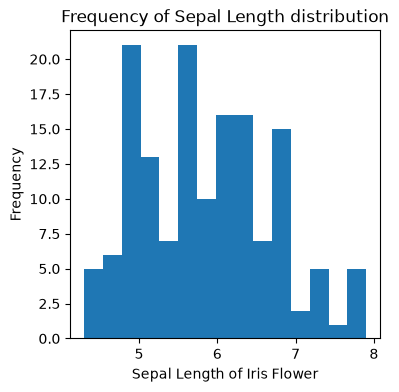

In [43]:
iris_df["SepalLengthCm"].plot(
    kind= "hist", 
    title= "Frequency of Sepal Length distribution", 
    bins= 15, 
    figsize= (4, 4), 
    xlabel= "Sepal Length of Iris Flower")

<Axes: xlabel='SepalLengthCm', ylabel='PetalLengthCm'>

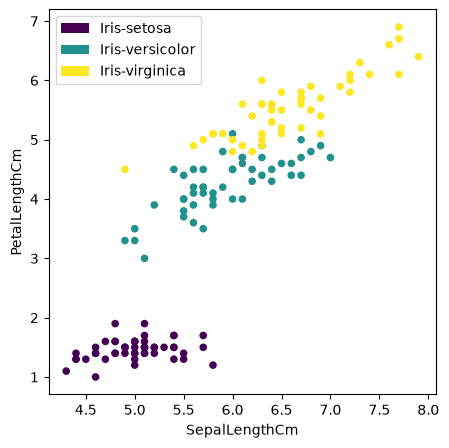

In [44]:
iris_df.plot(kind= "scatter", x= "SepalLengthCm", y= "PetalLengthCm", c= "Species", figsize = (5, 5))

<Axes: >

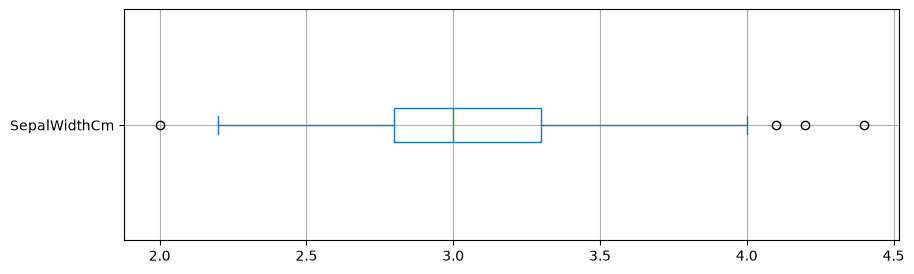

In [41]:
iris_df.plot(kind="box", column = "SepalWidthCm", vert= False, grid= True, figsize= (10, 3))

6. Correlation Matrix
    * Calculate the correlation matrix for the numerical features and create a heatmap to visualize the correlations using seaborn.

In [47]:
correlation = iris_df.corr(numeric_only= True).round(3)
correlation

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,sepal_petal_ratio
SepalLengthCm,1.000,-0.109,0.872,0.818,-0.699
SepalWidthCm,-0.109,1.000,-0.421,-0.357,0.588
PetalLengthCm,0.872,-0.421,1.000,0.963,-0.935
PetalWidthCm,0.818,-0.357,0.963,1.000,-0.896
sepal_petal_ratio,-0.699,0.588,-0.935,-0.896,1.000


<Axes: >

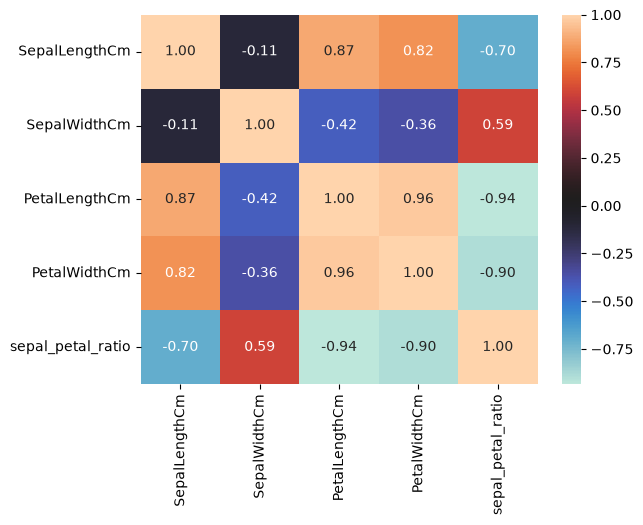

In [ ]:
sns.heatmap(data = correlation, cmap= "icefire", annot= True, fmt= ".2f")

### Dataset 02 : House Prices Dataset
The dataset includes 79 explanatory variables that describe aspects of residential homes.
#### Problem 1: Data Exploration with Pandas
1. Load the House Prices dataset using Pandas and perform initial exploration:
    * Display the first and last 5 rows.
    * Display the data types of each column.
    * Check for missing values and calculate the percentage of missing data for each column.
    * Summarize the statistical properties of the numerical columns using describe().

In [3]:
houseprice_df = pd.read_csv("housepricetrain.csv", index_col= "Id")

In [4]:
#Display the first and last 5 rows.
houseprice_df.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,
1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
houseprice_df.tail()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
Id,,,,,,,,,,,,,,,,,,,,,
1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,Inside,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


In [6]:
houseprice_df.shape

(1460, 80)

In [7]:
# Display the data types of each column.
houseprice_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 1 to 1460
Data columns (total 80 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MSSubClass     1460 non-null   int64  
 1   MSZoning       1460 non-null   str    
 2   LotFrontage    1201 non-null   float64
 3   LotArea        1460 non-null   int64  
 4   Street         1460 non-null   str    
 5   Alley          91 non-null     str    
 6   LotShape       1460 non-null   str    
 7   LandContour    1460 non-null   str    
 8   Utilities      1460 non-null   str    
 9   LotConfig      1460 non-null   str    
 10  LandSlope      1460 non-null   str    
 11  Neighborhood   1460 non-null   str    
 12  Condition1     1460 non-null   str    
 13  Condition2     1460 non-null   str    
 14  BldgType       1460 non-null   str    
 15  HouseStyle     1460 non-null   str    
 16  OverallQual    1460 non-null   int64  
 17  OverallCond    1460 non-null   int64  
 18  YearBuilt      1460

In [8]:
len(houseprice_df)

1460

In [9]:
# Check for missing values and calculate the percentage of missing data for each column.
missing_value= houseprice_df.isna().sum()
missing_percent = missing_value/ len(houseprice_df) * 100
print(missing_percent.round(2))

MSSubClass        0.00
MSZoning          0.00
LotFrontage      17.74
LotArea           0.00
Street            0.00
                 ...  
MoSold            0.00
YrSold            0.00
SaleType          0.00
SaleCondition     0.00
SalePrice         0.00
Length: 80, dtype: float64


In [10]:
# Summarize the statistical properties of the numerical columns using describe().
stat = houseprice_df.describe()
stat

,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,46.549315,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,161.319273,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,0.000000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,0.000000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,1474.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


2. Based on the dataset, identify the following:

    * Columns that are categorical and numerical.
    * Any potential outliers in the numerical columns (use visualizations like boxplots).

In [11]:
print(f"The numerical columns of the Dataset includes the following\n {stat.columns}")
print(f"The categorical columns of the Dataset includes the following\n {houseprice_df.select_dtypes(include="str").columns}")

The numerical columns of the Dataset includes the following
 Index(['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces',
       'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF',
       'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal',
       'MoSold', 'YrSold', 'SalePrice'],
      dtype='str')
The categorical columns of the Dataset includes the following
 Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond

<Axes: >

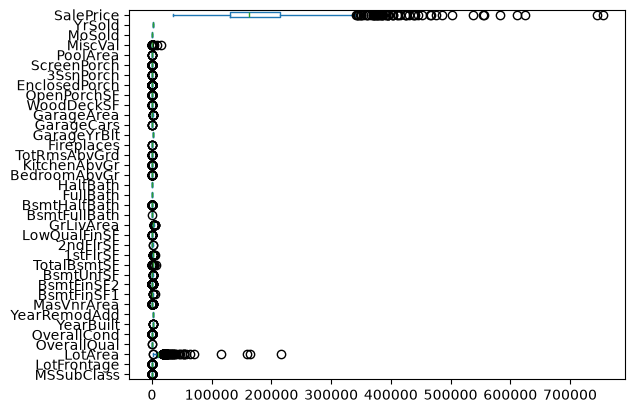

In [12]:
houseprice_df.plot(kind="box", vert= False)

### Problem 2: Data Manipulation with Pandas
1. Filter the dataset to include only houses where the SalePrice is above the 90th percentile.
2. Create a new calculated column: Price_Per_SqFt = SalePrice / GrLivArea.
3. Group the data by Neighborhood and calculate the mean and median for SalePrice.
4. Sort the dataset by Price_Per_SqFt and display the top 10 rows.

In [17]:
# Filter the dataset to include only houses where the SalePrice is above the 90th percentile.
quartile = houseprice_df["SalePrice"].quantile(0.9)
quartile_filter = houseprice_df[houseprice_df["SalePrice"] > quartile]
quartile_filter

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,Price_Per_SqFt
Id,,,,,,,,,,,,,,,,,,,,,
7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,Inside,...,NaN,NaN,NaN,0,8,2007,WD,Normal,307000,181.227863
12,60,RL,85.0,11924,Pave,NaN,IR1,Lvl,AllPub,Inside,...,NaN,NaN,NaN,0,7,2006,New,Partial,345000,148.450947
14,20,RL,91.0,10652,Pave,NaN,IR1,Lvl,AllPub,Inside,...,NaN,NaN,NaN,0,8,2007,New,Partial,279500,187.081660
21,60,RL,101.0,14215,Pave,NaN,IR1,Lvl,AllPub,Corner,...,NaN,NaN,NaN,0,11,2006,New,Partial,325300,136.910774
28,20,RL,98.0,11478,Pave,NaN,Reg,Lvl,AllPub,Inside,...,NaN,NaN,NaN,0,5,2010,WD,Normal,306000,179.577465
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1404,20,RL,49.0,15256,Pave,NaN,IR1,Lvl,AllPub,CulDSac,...,NaN,NaN,NaN,0,8,2007,WD,Normal,282922,193.252732
1418,60,RL,NaN,16545,Pave,NaN,IR1,Lvl,AllPub,Inside,...,NaN,NaN,NaN,0,5,2009,WD,Normal,340000,138.775510
1438,20,RL,96.0,12444,Pave,NaN,Reg,Lvl,AllPub,FR2,...,NaN,NaN,NaN,0,11,2008,New,Partial,394617,204.253106


In [16]:
# Create a new calculated column: Price_Per_SqFt = SalePrice / GrLivArea.
houseprice_df["Price_Per_SqFt"] = houseprice_df["SalePrice"] / houseprice_df["GrLivArea"]
houseprice_df.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,Price_Per_SqFt
Id,,,,,,,,,,,,,,,,,,,,,
1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,...,NaN,NaN,NaN,0,2,2008,WD,Normal,208500,121.929825
2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,...,NaN,NaN,NaN,0,5,2007,WD,Normal,181500,143.819334
3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,...,NaN,NaN,NaN,0,9,2008,WD,Normal,223500,125.139978
4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,...,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000,81.537566
5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,...,NaN,NaN,NaN,0,12,2008,WD,Normal,250000,113.739763


In [18]:
quartile_filter["Price_Per_SqFt"] = quartile_filter["SalePrice"] / quartile_filter["GrLivArea"]
quartile_filter.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,Price_Per_SqFt
Id,,,,,,,,,,,,,,,,,,,,,
7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,Inside,...,NaN,NaN,NaN,0,8,2007,WD,Normal,307000,181.227863
12,60,RL,85.0,11924,Pave,NaN,IR1,Lvl,AllPub,Inside,...,NaN,NaN,NaN,0,7,2006,New,Partial,345000,148.450947
14,20,RL,91.0,10652,Pave,NaN,IR1,Lvl,AllPub,Inside,...,NaN,NaN,NaN,0,8,2007,New,Partial,279500,187.081660
21,60,RL,101.0,14215,Pave,NaN,IR1,Lvl,AllPub,Corner,...,NaN,NaN,NaN,0,11,2006,New,Partial,325300,136.910774
28,20,RL,98.0,11478,Pave,NaN,Reg,Lvl,AllPub,Inside,...,NaN,NaN,NaN,0,5,2010,WD,Normal,306000,179.577465


In [19]:
# Group the data by Neighborhood and calculate the mean and median for SalePrice.
houseprice_neighbour = houseprice_df.groupby("Neighborhood")["SalePrice"].agg(["mean", "median"])
houseprice_neighbour

,mean,median
Neighborhood,,
Blmngtn,194870.882353,191000.0
Blueste,137500.000000,137500.0
BrDale,104493.750000,106000.0
BrkSide,124834.051724,124300.0
ClearCr,212565.428571,200250.0
CollgCr,197965.773333,197200.0
Crawfor,210624.725490,200624.0
Edwards,128219.700000,121750.0
Gilbert,192854.506329,181000.0


In [20]:
# Sort the dataset by Price_Per_SqFt and display the top 10 rows.
sort_houseprice = houseprice_df.sort_values(by= "Price_Per_SqFt")
sort_houseprice.head()

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,...,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice,Price_Per_SqFt
Id,,,,,,,,,,,,,,,,,,,,,
1299,60,RL,313.0,63887,Pave,NaN,IR3,Bnk,AllPub,Corner,...,Gd,NaN,NaN,0,1,2008,New,Partial,160000,28.358738
31,70,C (all),50.0,8500,Pave,Pave,Reg,Lvl,AllPub,Inside,...,NaN,MnPrv,NaN,0,7,2008,WD,Normal,40000,30.372058
1063,190,RM,85.0,13600,Pave,Grvl,Reg,Lvl,AllPub,Inside,...,NaN,NaN,NaN,0,9,2007,WD,Normal,90000,38.510911
969,50,RM,50.0,5925,Pave,NaN,Reg,Lvl,AllPub,Inside,...,NaN,GdWo,NaN,0,5,2009,WD,Abnorml,37900,39.152893
524,60,RL,130.0,40094,Pave,NaN,IR1,Bnk,AllPub,Inside,...,NaN,NaN,NaN,0,10,2007,New,Partial,184750,39.510265


### Problem 3: Handling Missing Data and Imputation
1. Identify columns with missing values.
2. Impute the missing values:
    * For numerical columns, replace missing values with the median.
    * For categorical columns, replace missing values with the most frequent value.
3. Justify your choice of imputation methods and check if any missing data remains.

In [21]:
for i in houseprice_df.columns:
    nullvalue= houseprice_df[i].isna().sum()
    if nullvalue == 0:
        continue
    print(f"{i} = {nullvalue}")

LotFrontage = 259
Alley = 1369
MasVnrType = 872
MasVnrArea = 8
BsmtQual = 37
BsmtCond = 37
BsmtExposure = 38
BsmtFinType1 = 37
BsmtFinType2 = 38
Electrical = 1
FireplaceQu = 690
GarageType = 81
GarageYrBlt = 81
GarageFinish = 81
GarageQual = 81
GarageCond = 81
PoolQC = 1453
Fence = 1179
MiscFeature = 1406


In [23]:
houseprice_fillna = houseprice_df.copy()
# For numerical columns, replace missing values with the median.
numerical_column = houseprice_fillna.select_dtypes(include=["int64", "float64"])

for i in numerical_column.columns:
    nullvalue= houseprice_fillna[i].isna().sum()
    if nullvalue == 0:
        continue
    houseprice_fillna.loc[:,i] = houseprice_fillna.fillna(value= (houseprice_fillna[i].median()))

for i in numerical_column.columns:
    nullvalue= houseprice_fillna[i].isna().sum()
    if nullvalue == 0:
        continue
    #print(f"{i} = {nullvalue}")
# For categorical columns, replace missing values with the most frequent value.
catergorical_column = houseprice_df.select_dtypes(include="str")

for i in catergorical_column.columns:
    nullvalue= houseprice_fillna[i].isna().sum()
    if nullvalue == 0:
        continue
    houseprice_fillna.loc[:,i] = houseprice_fillna.fillna(value= (houseprice_fillna[i].mode()[0]))

Problem 4: Numpy Array Operations

Convert the numerical columns (such as LotArea, YearBuilt, GrLivArea, SalePrice, etc.) into a NumPy array.

Perform the following NumPy operations on the array:
* Compute the mean and standard deviation of each column.
* Normalize the data using min-max scaling and z-score normalization.
* Compute the dot product between two numerical columns of your choice

In [24]:
#Convert the numerical columns (such as LotArea, YearBuilt, GrLivArea, SalePrice, etc.) into a NumPy array.
numerical_array = numerical_column.to_numpy()
print(numerical_array)

[[6.00000000e+01 6.50000000e+01 8.45000000e+03 ... 2.00800000e+03
  2.08500000e+05 1.21929825e+02]
 [2.00000000e+01 8.00000000e+01 9.60000000e+03 ... 2.00700000e+03
  1.81500000e+05 1.43819334e+02]
 [6.00000000e+01 6.80000000e+01 1.12500000e+04 ... 2.00800000e+03
  2.23500000e+05 1.25139978e+02]
 ...
 [7.00000000e+01 6.60000000e+01 9.04200000e+03 ... 2.01000000e+03
  2.66500000e+05 1.13888889e+02]
 [2.00000000e+01 6.80000000e+01 9.71700000e+03 ... 2.01000000e+03
  1.42125000e+05 1.31841373e+02]
 [2.00000000e+01 7.50000000e+01 9.93700000e+03 ... 2.00800000e+03
  1.47500000e+05 1.17436306e+02]]


In [27]:
#Numpy Operation
array_mean= numerical_array.mean(axis=0)
stddev = numerical_array.std(axis=0)
print("Mean of array", array_mean, "Standard Deviation of array", stddev)

#Min-max Scaling
col_min= numerical_array.min()
col_max= numerical_array.max()
min_max_scaled= (numerical_array - col_min) / (col_max - col_min)

#z_score
z_score = (numerical_array - array_mean) / (stddev + 1e-8)

#DOT product 
col_dot_product = np.dot(houseprice_fillna.LotArea, houseprice_fillna.LotFrontage)
print("Product of lot area and lot frontage", col_dot_product)

Mean of array [5.68972603e+01            nan 1.05168281e+04 6.09931507e+00
 5.57534247e+00 1.97126781e+03 1.98486575e+03            nan
 4.43639726e+02 4.65493151e+01 5.67240411e+02 1.05742945e+03
 1.16262671e+03 3.46992466e+02 5.84452055e+00 1.51546370e+03
 4.25342466e-01 5.75342466e-02 1.56506849e+00 3.82876712e-01
 2.86643836e+00 1.04657534e+00 6.51780822e+00 6.13013699e-01
            nan 1.76712329e+00 4.72980137e+02 9.42445205e+01
 4.66602740e+01 2.19541096e+01 3.40958904e+00 1.50609589e+01
 2.75890411e+00 4.34890411e+01 6.32191781e+00 2.00781575e+03
 1.80921196e+05 1.20572878e+02] Standard Deviation of array [4.22860820e+01            nan 9.97784611e+03 1.38252284e+00
 1.11241818e+00 3.01925588e+01 2.06383353e+01            nan
 4.55941866e+02 1.61264017e+02 4.41715605e+02 4.38555057e+02
 3.86455322e+02 4.36378914e+02 4.86064268e+01 5.25300394e+02
 5.18732867e-01 2.38670868e-01 5.50727099e-01 5.02713131e-01
 8.15498620e-01 2.20262727e-01 1.62483655e+00 6.44445572e-01
           

Problem 5: Data Visualization

Using Matplotlib and/or Seaborn, visualize the following:

* Distribution of SalePrice using a histogram.
* Box plot of SalePrice grouped by OverallQual (overall quality of the house).
* Scatter plot between GrLivArea (Above-ground living area) and SalePrice. Analyze the relationship.
* Plot a correlation heatmap for the numerical columns.

<Axes: title={'center': 'Frequency of Sales Price'}, xlabel='Sales Price', ylabel='Frequency'>

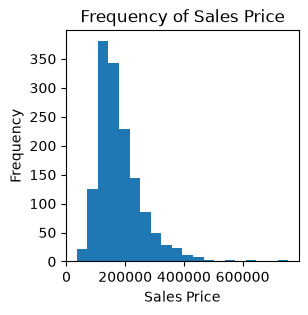

In [29]:
houseprice_fillna["SalePrice"].plot(
    kind= "hist", 
    title= "Frequency of Sales Price", 
    bins= 20, 
    figsize= (3, 3), 
    xlabel= "Sales Price")

<Axes: >

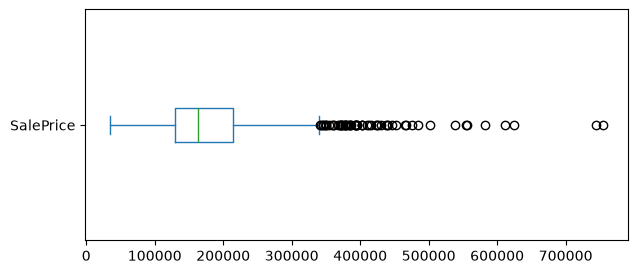

In [36]:
houseprice_fillna.plot(
    kind="box",
    x= "OverallQual",
    y= "SalePrice",
    figsize= (7, 3),
    vert= False
)

<Axes: xlabel='GrLivArea', ylabel='SalePrice'>

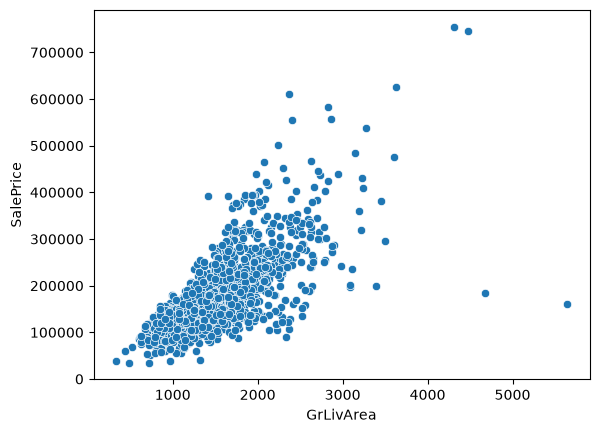

In [41]:
sns.scatterplot(
    data= houseprice_fillna,
    x= "GrLivArea",
    y= "SalePrice"
)

<Axes: >

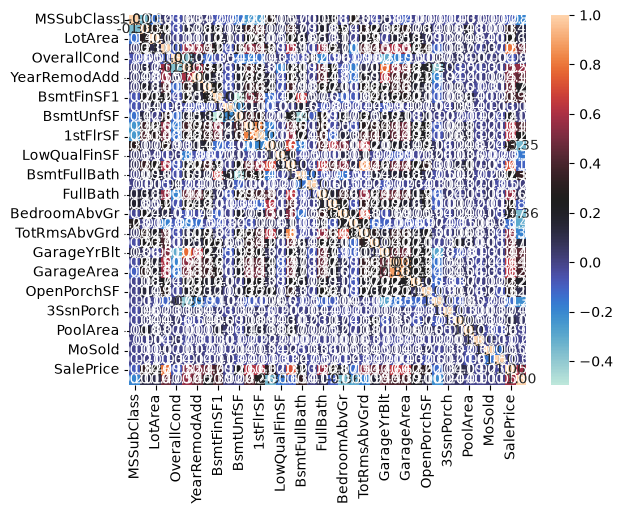

In [44]:
correlation = houseprice_fillna.corr(numeric_only=True).round(2)
sns.heatmap(data = correlation, cmap= "icefire", annot= True, fmt= ".2f")

Problem 6: Aggregation and Transformation

- Perform a groupby operation on Neighborhood and calculate the mean and median for SalePrice.
- Use the apply() function to create a custom transformation for SalePrice (e.g., scaling or transformation).
- Aggregate multiple statistical values (e.g., mean, median, and count) for SalePrice grouped by OverallQual.

In [45]:
houseprice_fillna.columns

Index(['MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley',
       'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope',
       'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle',
       'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle',
       'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea',
       'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond',
       'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC',
       'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd',
       'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt',
       'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond',
       'PavedDrive', 'Wo

In [51]:
neighbour_sale = houseprice_fillna.groupby("Neighborhood")["SalePrice"].agg(["mean", "median"])
neighbour_sale

,mean,median
Neighborhood,,
Blmngtn,194870.882353,191000.0
Blueste,137500.000000,137500.0
BrDale,104493.750000,106000.0
BrkSide,124834.051724,124300.0
ClearCr,212565.428571,200250.0
CollgCr,197965.773333,197200.0
Crawfor,210624.725490,200624.0
Edwards,128219.700000,121750.0
Gilbert,192854.506329,181000.0


In [52]:
houseprice_fillna['SalePrice_Log'] = houseprice_fillna['SalePrice'].apply(lambda x: np.log(x) if x > 0 else 0)

In [55]:
price_stats_by_qual = houseprice_fillna.groupby('OverallQual')['SalePrice'].agg(
    Mean_Price='mean',
    Median_Price='median',
    Total_Houses='count'
).reset_index()
price_stats_by_qual

,OverallQual,Mean_Price,Median_Price,Total_Houses
0,1,50150.000000,50150.0,2
1,2,51770.333333,60000.0,3
2,3,87473.750000,86250.0,20
3,4,108420.655172,108000.0,116
4,5,133523.347607,133000.0,397
5,6,161603.034759,160000.0,374
6,7,207716.423197,200141.0,319
7,8,274735.535714,269750.0,168
8,9,367513.023256,345000.0,43
9,10,438588.388889,432390.0,18
